# Wine Dataset - Data Science Model
**XYZ Company**

Tasks:
1. Import the wine dataset using sklearn
2. Split the data into train and test set
3. Train the model
4. Make predictions
5. Check the performance of the model using `r2_score` , `rmse` 

In [30]:
import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.preprocessing import StandardScaler    
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score , mean_squared_error

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

## 1. Import the wine dataset (sklearn) and load it with pandas

In [31]:
# Import the wine dataset from sklearn and save it as a CSV file (first run only)
if not os.path.exists("wine_data.csv"):
    wine_bunch = load_wine()
    wine_df = pd.DataFrame(wine_bunch.data, columns=wine_bunch.feature_names)
    wine_df["target"] = wine_bunch.target
    wine_df.to_csv("wine_data.csv", index=False)
    print("wine_data.csv created")

In [32]:
# Load the data with pandas
df = pd.read_csv("wine_data.csv")

print("Shape:", df.shape)
df.head()

Shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### Quick look at the data

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [34]:
print("Missing values:", int(df.isnull().sum().sum()))
df.describe().T.round(2)

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


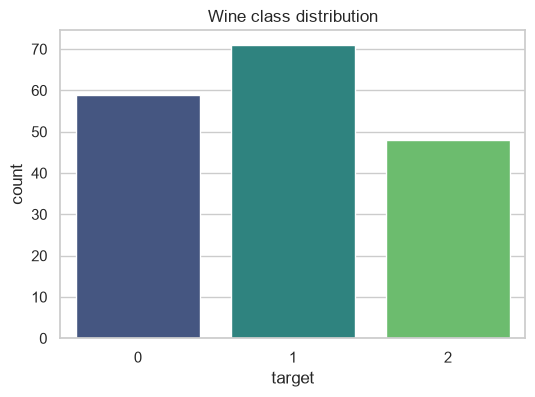

In [35]:
plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df, palette="viridis")
plt.title("Wine class distribution")
plt.show()

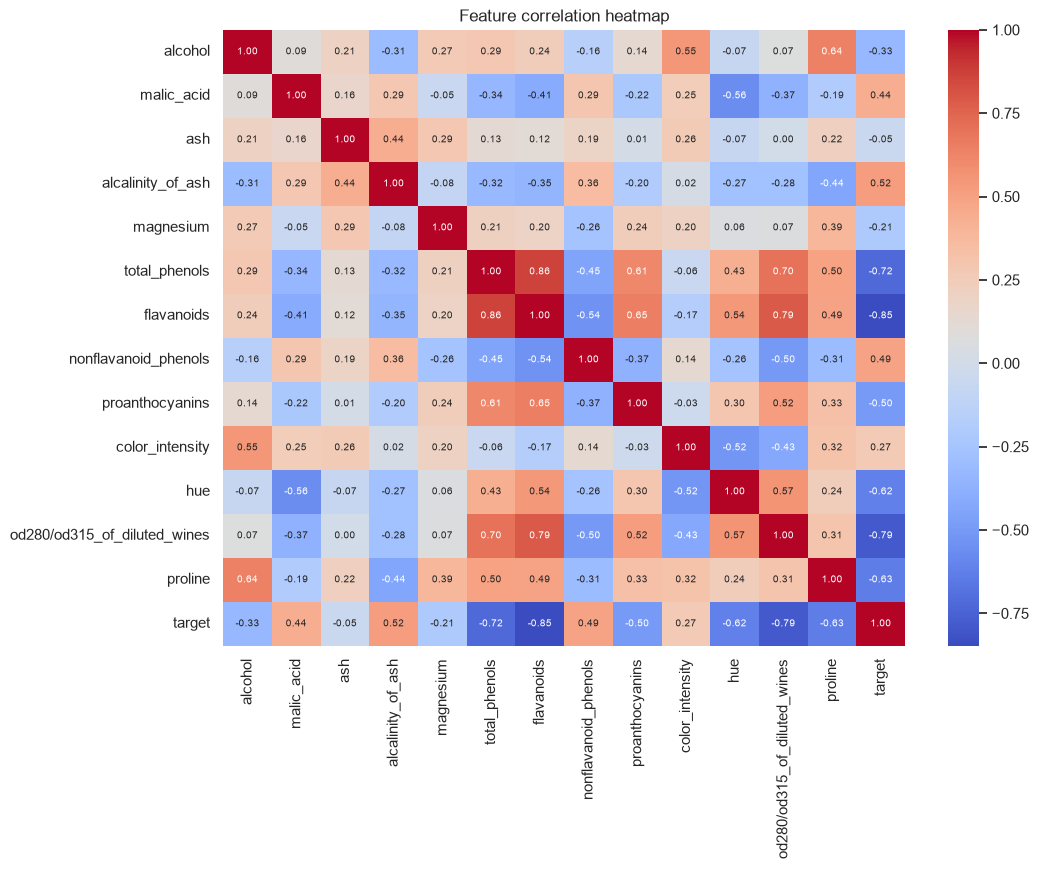

In [36]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Feature correlation heatmap")
plt.show()

## 2. Split the data into train and test set

In [37]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (142, 13) | Test: (36, 13)


## 3. Train the model
Several regression models are trained and compared; the best one (highest test R2) is kept.

In [40]:
models = {
    "LinearRegression": {
        "model": LinearRegression(),
        "param_grid": {}
    },
    "RandomForestRegressor": {
        "model": RandomForestRegressor(),
        "param_grid": {
            "n_estimators": [50, 100, 200],
            "max_depth": [None, 5, 10, 15],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4]
        }
    },
    "DecisionTreeRegressor": {
        "model": DecisionTreeRegressor(),
        "param_grid": {
            "max_depth": [None, 5, 10, 15],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4]
        }
    },
    "GradientBoostingRegressor": {
        "model": GradientBoostingRegressor(),
        "param_grid": {
            "n_estimators": [50, 100, 200],
            "learning_rate": [0.01, 0.1, 0.2],
            "max_depth": [3, 5, 7]
        }
    }
}

In [41]:
best_models = []

## 4. Make predictions

In [42]:
for name, config in models.items():
    print(f"Training {name}...")

    grid = GridSearchCV(
        estimator=config["model"],
        param_grid=config["param_grid"],
        cv=5,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )
    grid.fit(X_train, y_train)

    y_pred = grid.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"Best parameters for {name}: {grid.best_params_}")
    print(f"RMSE for {name}: {rmse}")
    print(f"R2 Score for {name}: {r2}")

    best_models.append({
        "model": name,
        "best_params": grid.best_params_,
        "rmse": rmse,
        "r2": r2
    })

Training LinearRegression...
Best parameters for LinearRegression: {}
RMSE for LinearRegression: 0.2617890078719137
R2 Score for LinearRegression: 0.8825140263270383
Training RandomForestRegressor...
Best parameters for RandomForestRegressor: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 50}
RMSE for RandomForestRegressor: 0.22989930359576727
R2 Score for RandomForestRegressor: 0.9093936746391678
Training DecisionTreeRegressor...
Best parameters for DecisionTreeRegressor: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5}
RMSE for DecisionTreeRegressor: 0.408248290463863
R2 Score for DecisionTreeRegressor: 0.7142857142857142


In [46]:
results_df = pd.DataFrame(best_models)

In [47]:
results_df

,model,best_params,rmse,r2
0,LinearRegression,{},0.261789,0.882514
1,RandomForestRegressor,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s...",0.229899,0.909394
2,DecisionTreeRegressor,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",0.408248,0.714286


## 5. Check the performance using r2_score , rmse

In [49]:
results_df.sort_values(
    by=["r2", "rmse"],
    ascending=[False, True],    
    inplace=True
)
results_df

,model,best_params,rmse,r2
1,RandomForestRegressor,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s...",0.229899,0.909394
0,LinearRegression,{},0.261789,0.882514
2,DecisionTreeRegressor,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",0.408248,0.714286


In [50]:
import joblib 
best_row= results_df.sort_values(by=["rmse", "r2"], ascending=[True, False]).iloc[0]

In [51]:
best_row

model                                      RandomForestRegressor
best_params    {'max_depth': 5, 'min_samples_leaf': 1, 'min_s...
rmse                                                    0.229899
r2                                                      0.909394
Name: 1, dtype: object

In [52]:
best_models_name = best_row["model"]

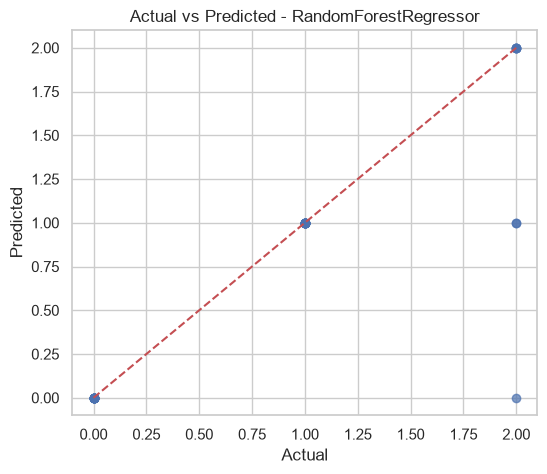

In [53]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title(f"Actual vs Predicted - {best_models_name}")
plt.show()

In [54]:
best_model_config = models[best_models_name]

In [55]:
best_model_config

{'model': RandomForestRegressor(),
 'param_grid': {'n_estimators': [50, 100, 200],
  'max_depth': [None, 5, 10, 15],
  'min_samples_split': [2, 5, 10],
  'min_samples_leaf': [1, 2, 4]}}

In [56]:
final_model = best_model_config["model"].set_params(**best_row["best_params"])

In [57]:
final_model.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number 

## Save the best model

In [ ]:
joblib.dump(best_model, "best_wine_model.pkl")
print("Saved: best_wine_model.pkl")

Saved: best_wine_model.pkl


In [59]:
joblib.load("best_wine_model.pkl").predict(X_test)

array([0.   , 0.   , 1.34 , 0.03 , 1.   , 0.   , 1.   , 2.   , 0.945,
       0.915, 0.105, 1.345, 0.   , 1.345, 0.   , 1.   , 1.   , 1.   ,
       0.   , 1.   , 0.   , 0.83 , 1.115, 1.985, 1.99 , 2.   , 0.99 ,
       0.87 , 1.   , 0.   , 0.03 , 0.995, 1.88 , 0.   , 0.015, 0.   ])